In [11]:
import warnings

warnings.simplefilter("ignore")

In [12]:
pwd

'/home/shashi/Amitror/GRB140304A/GBM'

In [13]:
%%capture
import matplotlib.pyplot as plt
import numpy as np

np.seterr(all="ignore")

from threeML import *
from threeML.io.package_data import get_path_of_data_file

In [14]:
from jupyterthemes import jtplot

%matplotlib inline
jtplot.style(context="talk", fscale=1, ticks=True, grid=False)

silence_warnings()

set_threeML_style()

In [15]:
cspec_file = "/home/shashi/Amitror/GRB140304A/GBM/current/glg_cspec_n5_bn140304557_v00.pha"
tte_file = "/home/shashi/Amitror/GRB140304A/GBM/current/glg_tte_n5_bn140304557_v00.fit"
gbm_rsp = "/home/shashi/Amitror/GRB140304A/GBM/current/glg_cspec_n5_bn140304557_v02.rsp"


gbm_cspec = TimeSeriesBuilder.from_gbm_cspec_or_ctime(
    "nai5_cspec", cspec_or_ctime_file=cspec_file, rsp_file=gbm_rsp)

gbm_tte = TimeSeriesBuilder.from_gbm_tte(
    "nai5_tte", tte_file=tte_file, rsp_file=gbm_rsp)

Loading PHAII Spectra:   0%|                           | 0/2394 [00:00<?, ?it/s]

In [16]:
import matplotlib as mpl
mpl.rcParams['axes.unicode_minus'] = True
plt.rcParams['font.family'] = 'DejaVu Sans'

Finding best polynomial Order:   0%|                      | 0/5 [00:00<?, ?it/s]

Fitting GBM_NAI_05 background:   0%|                    | 0/128 [00:00<?, ?it/s]

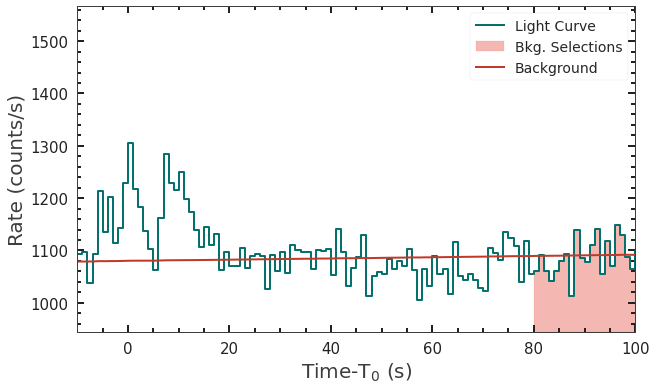

In [17]:
gbm_tte.set_background_interval("-100 - -20", "80 - 150")
fig = gbm_tte.view_lightcurve(start=-100, stop=150)

fig.set_size_inches(10, 6)

plt.ylabel('Rate (counts/s)',size=20)
plt.xlabel(r'Time-T$_{0}$ (s)',size=20)
plt.tick_params(direction='in', which = 'major', length=7, width=2, top=True, right=True, colors='k', grid_color='k', grid_alpha=0.9, labelsize=15)
plt.tick_params(direction='in', which = 'minor', length=4, width=2, top=True, right=True, colors='k', grid_color='k', grid_alpha=0.9, labelsize=15)

plt.legend(loc="best", fontsize = 14, ncol = 1)
plt.gca().spines['top'].set_visible(True)
plt.gca().spines['right'].set_visible(True)
plt.xlim(-10, 100)
# plt.ylim(1100, 1600)
plt.minorticks_on()

# plt.savefig('lc.pdf',bbox_inches='tight',overwrite=True)

In [18]:
gbm_tte.create_time_bins(start=-10, stop=50.0, method="bayesblocks", p0=0.01, use_background=True)

In [19]:
gbm_tte.bins.display

<bound method TimeIntervalSet.display of        Start       Stop   Duration   Midpoint
0  -9.999762  -0.662005   9.337757  -5.330883
1  -0.662005   1.481452   2.143457   0.409724
2   1.481452   6.682748   5.201296   4.082100
3   6.682748  12.680607   5.997859   9.681678
4  12.680607  49.997978  37.317371  31.339293>